## Prepare for analysis - get models

**Load modules**

In [1]:
import reframed
import pandas as pd
import matplotlib.pyplot as plt

import json
import sys

sys.path.append('../scripts_python/Venturelli2018')
sys.path.append('../scripts_python/Guillen2021')
sys.path.append("../scripts_python/")
import prepare_files_for_simulation
import prepare_models_venturelli2018, prepare_models_guillen2021
import make_optimized_media

import general

In [2]:
%load_ext autoreload
%autoreload 2

#### Run this the first time you run the script (for gut microbiome)

### E. coli auxotrophs (Guillen et al. 2021) 

In [3]:
prepare_models_guillen2021.main()

INFO     | STARTING SCRIPT FOR MODEL PREPARATION
INFO     | Downloading and loading iML1515 model from Bernstein et al (2023) github repository...
INFO     | Adjusting biomass stoichiometry for butanoate from -2e-06 to -0.002
INFO     | Mapping gene IDs to gene names...
INFO     | Loading relative abundance data...
INFO     | Creating single knockout models for each gene in relative abundance data...
INFO     | SAVING DATA.
INFO     | Saving gene ID to name mapping from model in ../data/Guillen2021/generated/gene_id2name.tsv.
INFO     | Saving gene knockout in model for gene name ../models/Guillen2021/model_gene_KO.json. 
 NB: this accounted for effect of knockout of regulatory genes like panZ.
INFO     | SAVING MODELS.
INFO     | Saving all mutant models in ../models/Guillen2021/strains/...
INFO     | Saving top 7 most abundant strains in ../models/Guillen2021/top_7_strains/...


**Load model and data**

In [4]:
models_ecoli = general.load_models_guillen2021()

with open("../models/Guillen2021/model_gene_KO.json", mode='r') as reader:
    gene_ko_data = json.load(reader)

relative_abundance = pd.read_csv("../data/Guillen2021/relative_abundance.csv",index_col=0)
# NB! yhhK in data == panZ in paper
relative_abundance.index =relative_abundance.index.map(lambda x:x if x!="yhhK" else "panZ")

INFO     | Loading models from Guillen et al (2021)...


**Experimental relative abundance from Guillen et al (2021)**

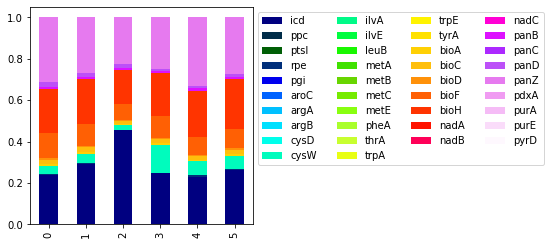

In [5]:
ax = relative_abundance.T.plot.bar(stacked=True,cmap="gist_ncar",figsize=(4,4))

plt.legend(loc="upper left", ncol=len(relative_abundance.index)/8,bbox_to_anchor=(1,1))
plt.show()

In [6]:
relative_abundance.T.mean().sort_values(ascending=False).head(10)

icd     0.287848
panZ    0.276678
bioH    0.211130
bioF    0.098526
cysW    0.062219
bioC    0.020200
panD    0.015948
panB    0.009927
bioA    0.007043
bioD    0.005411
dtype: float64

In [7]:

gene1 = "panD"
gene2 = "panD"

for rxn in models_ecoli[f"mutant_{gene1}"].get_reactions_by_gene(gene_ko_data[gene2]):
    lb = models_ecoli[f"mutant_{gene1}"].reactions[rxn].lb
    ub = models_ecoli[f"mutant_{gene1}"].reactions[rxn].ub
    print(f"{rxn} flux constrained for {gene1} reactions: {(lb,ub)}")

gene1 = "panD"
gene2 = "icd"
for rxn in models_ecoli[f"mutant_{gene1}"].get_reactions_by_gene(gene_ko_data[gene2]):
    lb = models_ecoli[f"mutant_{gene1}"].reactions[rxn].lb
    ub = models_ecoli[f"mutant_{gene1}"].reactions[rxn].ub
    print(f"{rxn} flux NOT constrained for {gene2}: {(lb,ub)}")

R_ASP1DC flux constrained for panD reactions: (0.0, 0.0)
R_ICDHyr flux NOT constrained for icd: (-inf, inf)


### Gut microbiome (Venturelli et al. 2018) 

In [8]:
prepare_models_venturelli2018.main()

INFO     | LOAD DATA AND MODELS
INFO     | load media data and models from '../models/Venturelli2018/species_used/'...
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom_preanalysis/lib/python3.8/site-packages/reframed/io/sbml.py:579: UserWarning: Could not extract annotation from http://identifiers.org/inchi/InChI=1S/C12H21N3O13P2/c13-8-1-2-15(12(20)14-8)11-10(19)9(18)7(27-11)5-26-30(23,24)28-29(21,22)25-4-6(17)3-16/h1-2,6-7,9-11,16-19H,3-5H2,(H,21,22)(H,23,24)(H2,13,14,20)/
  warn(f'Could not extract annotation from {term.getResourceURI(i)}')
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom_preanalysis/lib/python3.8/site-packages/reframed/io/sbml.py:579: UserWarning: Could not extract annotation from http://identifiers.org/inchi/InChI=1S/C11H12Cl2N2O5/c12-10(13)11(18)14-8(5-16)9(17)6-1-3-7(4-2-6)15(19)20/h1-4,8-10,16-17H,5H2,(H,14,18)/
  warn(f'Could not extract annotation from {term.getResourceURI(i)}')
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom_preanalysis/lib/py

Set parameter Username


INFO     | Set parameter Username


Academic license - for non-commercial use only - expires 2026-03-27


INFO     | Academic license - for non-commercial use only - expires 2026-03-27
INFO     | Results: 
 M_Bacteroides_uniformis_ATCC_8492: R_EX_biomass__40__e__41__ = 12.579094463276023 
M_Bacteroides_vulgatus_ATCC_8482: R_EX_biomass__40__e__41__ = 21.924067089837525 
M_Collinsella_aerofaciens_ATCC_25986: R_EX_biomass__40__e__41__ = 8.42061724134823 
M_Faecalibacterium_prausnitzii_A2_165: R_EX_biomass__40__e__41__ = 24.151934992650407 
M_Eggerthella_lenta_DSM_2243: R_EX_biomass__40__e__41__ = 1.600892420812452 
M_Prevotella_copri_CB7_DSM_18205: R_EX_biomass__40__e__41__ = 6.994180254517099 
M_Clostridium_hiranonis_TO_931_DSM_13275: R_EX_biomass__40__e__41__ = 2.6575536007582694 
M_Eubacterium_rectale_ATCC_33656: R_EX_biomass__40__e__41__ = 16.101056672095726 
M_Desulfovibrio_piger_ATCC_29098: R_EX_biomass__40__e__41__ = 2.2407509538077033 
M_Bacteroides_ovatus_ATCC_8483: R_EX_biomass__40__e__41__ = 15.867792095109984 
M_Bacteroides_thetaiotaomicron_VPI_5482: R_EX_biomass__40__e__41__ = 21

## Prepare for analysis - Make media

### E.coli auxotrophs

In [9]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")

The medium used in the study was M9 medium, which is already defined.

In [10]:
media_db[media_db.medium=="M9"].to_csv("../data/Guillen2021/generated/media_db.tsv",sep="\t",index=None)

### Gut microbiome models

1. Test growth on LB medium
2. Define a minimal media where all models can grow

In [11]:
make_optimized_media.main()

INFO     | STARTING SCRIPT FOR FINDING MINIMAL MEDIA FOR COMMUNITY
INFO     | Loading models from Venturelli et al (2018)...
INFO     | Loading data and LB medium from carveme media database...
INFO     | Finding optimized medium for all models...
INFO     | Started finding medium for M_Bacteroides_uniformis_ATCC_8492
INFO     | Started finding medium for M_Bacteroides_vulgatus_ATCC_8482
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom_preanalysis/lib/python3.8/site-packages/reframed/core/elements.py:62: UserWarning: Atomic weight not listed for elements: {'X'}
  warn(f"Atomic weight not listed for elements: {missing}")
INFO     | 	 M_Bacteroides_vulgatus_ATCC_8482 cannot grow: -0.0	 Minimal media fobj: 345328.5146
INFO     | 	 M_Bacteroides_vulgatus_ATCC_8482: R_EX_biomass__40__e__41__ = 0.5744693271554725 
 at cutoff 1000.0

INFO     | Started finding medium for M_Collinsella_aerofaciens_ATCC_25986
INFO     | 	 M_Collinsella_aerofaciens_ATCC_25986 cannot grow: -0.0	 Minimal medi

### Prepare files for simulations

In [4]:
prepare_files_for_simulation.main()

INFO     | STARTING SCRIPT FOR PREPARING FILES FOR SIMULATION
INFO     | LOADING DATA...
INFO     | Loading relative abundance data from Guillen et al (2021)...
INFO     | Loading models and data from Venturelli et al (2018)...
INFO     | Loading models from Venturelli et al (2018)...
INFO     | CREATING DATA FILES FOR SIMULATION...
INFO     | Creating media db for SMETANA from environment used in Venturelli et al (2018)...
INFO     | Creating community df for Venturelli et al (2018) for SteadierCom, SteadyCom, and SMETANA ...
INFO     | Creating community df for Guillen et al (2021) for SteadierCom, SteadyCom, and SMETANA ...
INFO     | Creating pairwise df for Venturelli et al (2018) for SteadierCom, SteadyCom, and SMETANA ...
INFO     | SAVING DATA...
INFO     | Saving media database for SMETANA in ../data/Venturelli2018/generated/media_db_smetana.tsv 
 Saving SMETANA community data for Venturelli et al (2018) in ../data/Venturelli2018/generated/communities_smetana.tsv 
 Saving SMET